# Stranded: a quantum cognition model of evacuation decisions

**IBM Qiskit Fall Fest 2026, University of Waterloo.**

People don't always decide the way classical probability predicts. Two well-known examples: the order of two pieces of evidence can change a judgment, and people can act differently when unsure than under *either* certain outcome. Quantum probability is one established mathematical way to model these effects (Busemeyer and Bruza, 2012).

We put such a model in charge of a survivor facing a volcanic eruption, then compare it with two controls in identical worlds. We also test the world itself against the real 2021 eruption of La Soufriere, St Vincent.

**What is real, and what is a model**

| Claim | Status |
|---|---|
| The 2-qubit circuit gives the probabilities we say it does | **Checked here**, exactly |
| It behaves differently from its controls | **Measured here**, in simulation |
| People's brains are quantum | **Not claimed.** This is mathematics that can fit decision data |
| Quantum decisions are better | **Not claimed, and not found here** |
| Runs on real IBM hardware | **No.** We use `FakeTorino`, a simulator with a saved noise snapshot |
| Stress is physical decoherence in a person | **No.** It's a modelling choice |
| The classical mind uses time-use survey data | **No.** Its weights are set by hand, though the data file is present |
| The survivor's survival rates describe real people | **No.** Body rates are assumptions |


In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import qiskit
from qiskit.quantum_info import Statevector

from mind.belief import prepare_belief, run_events
from mind.circuits import build_decision_circuit
from mind.config import ETA, EVENT_GATES
from mind.decoherence import decoherence_strength
from mind.model import bloch_vector, p_protect_closed_form

print("Qiskit", qiskit.__version__)
Q_SAFE, Q_DANGER = 0.69, 0.59  # Tversky and Shafir (1992): choosing to gamble again after a known win or a known loss.

Qiskit 2.6.1


## 1. The model

The mind uses two qubits:

- **Qubit 0 is the belief:** `|0>` means safe, `|1>` means danger. It starts from how safe the survivor feels.
- **Each warning sign rotates the belief.** A tremor rotates about the Y axis and a gas smell about the X axis.
- **A deliberation unitary `U` then acts on both qubits.** Measuring qubit 1 gives the decision: protect yourself, or carry on.

`U` is built so that with no interference it reproduces two conditional probabilities: `q_S`, the chance of protecting when certainly safe, and `q_D`, when certainly in danger. It has one free phase, `ETA`, which sets how strongly the two paths interfere.

In [2]:
circuit = build_decision_circuit(safety=0.85, events=["tremor", "gas_plume"], q_S=Q_SAFE, q_D=Q_DANGER, eta=ETA)
print(circuit.draw("text"))
print("Gates for each sign:", {k: (axis, round(angle, 3)) for k, (axis, angle) in EVENT_GATES.items() if k in ("tremor", "gas_plume", "storm", "find_food")})

     ┌────────────┐┌─────────┐┌──────────┐┌────┐   
q_0: ┤ Ry(0.7954) ├┤ Ry(π/3) ├┤ Rx(3π/5) ├┤0   ├───
     └────────────┘└─────────┘└──────────┘│  U │┌─┐
q_1: ─────────────────────────────────────┤1   ├┤M├
                                          └────┘└╥┘
c: 1/════════════════════════════════════════════╩═
                                                 0 
Gates for each sign: {'tremor': ('ry', 1.047), 'gas_plume': ('rx', 1.885), 'storm': ('ry', 1.047), 'find_food': ('ry', -0.785)}


## 2. Is the circuit right?

The game uses a closed-form equation, because it must decide quickly. So we first check that equation against an exact simulation of the Qiskit circuit, on many random inputs. If the two disagree, nothing after this section means anything.

In [3]:
def exact_from_circuit(safety, events, q_s=Q_SAFE, q_d=Q_DANGER):
    circuit = build_decision_circuit(safety, events, q_s, q_d, ETA).remove_final_measurements(inplace=False)
    return Statevector(circuit).probabilities([1])[1]  # Probability that the decision qubit reads 1: protect.


def closed_form(safety, events, lam=0.0, q_s=Q_SAFE, q_d=Q_DANGER):
    x, _, z = bloch_vector(run_events(prepare_belief(safety), events, lam))
    return p_protect_closed_form((1 - z) / 2, x, q_s, q_d, ETA)


rng = np.random.default_rng(2026)
signs = ["tremor", "gas_plume", "storm", "injury", "cold_night", "find_food"]
errors = []
for _ in range(300):
    safety = float(rng.uniform(0.05, 0.95))
    events = list(rng.choice(signs, size=int(rng.integers(0, 4))))
    q_s, q_d = sorted(rng.uniform(0.2, 0.8, 2))[::-1]
    errors.append(abs(exact_from_circuit(safety, events, q_s, q_d) - closed_form(safety, events, 0.0, q_s, q_d)))
print(f"Largest disagreement over {len(errors)} random cases: {max(errors):.2e}")
assert max(errors) < 1e-9

Largest disagreement over 300 random cases: 5.55e-16


## 3. Fitted, not predicted: the "uncertain" dip

Tversky and Shafir (1992) reported that 69% of people would gamble again after a known win and 59% after a known loss, but only 36% when they didn't yet know the result. A classical mixture must fall between 59% and 69%.

**`ETA` was solved to hit that 36%**, so the match below is a fit, not a prediction. The useful thing is the shape it then produces: a dip below both certain cases, which a classical mixture can't produce with any weights.

At even odds: quantum 0.360, classical mixture 0.640, reported by Tversky and Shafir 0.36


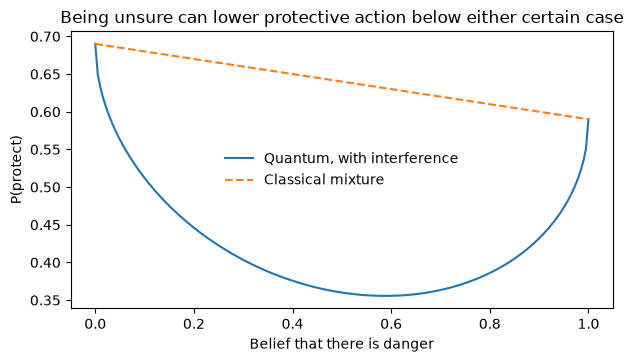

In [4]:
probabilities = np.linspace(0, 1, 201)
quantum = [p_protect_closed_form(p, 2 * np.sqrt(p * (1 - p)), Q_SAFE, Q_DANGER, ETA) for p in probabilities]
classical = (1 - probabilities) * Q_SAFE + probabilities * Q_DANGER
print(f"At even odds: quantum {p_protect_closed_form(0.5, 1.0, Q_SAFE, Q_DANGER, ETA):.3f}, classical mixture {0.5 * (Q_SAFE + Q_DANGER):.3f}, reported by Tversky and Shafir 0.36")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(probabilities, quantum, label="Quantum, with interference")
ax.plot(probabilities, classical, "--", label="Classical mixture")
ax.set_xlabel("Belief that there is danger")
ax.set_ylabel("P(protect)")
ax.set_title("Being unsure can lower protective action below either certain case")
ax.legend(frameon=False)
plt.show()

## 4. The order effect

Now the main test: **same person, same two warning signs, only the order swapped.** We also run the control, the same model with belief coherence removed after each sign, because a difference only matters if we know what it would be without interference.

In [5]:
from engine.agent import SurvivalAgent
from mind.quantum_mind import classical_mixture_decide, quantum_decide

start = SurvivalAgent().get_state()
print(f"Starting state: stress {start['stress']}, safety {start['needs']['safety']}\n")
print(f"{'Mind':<10}{'Order':<24}{'P(protect)':<12}Action")
for name, decide in (("Quantum", quantum_decide), ("Control", classical_mixture_decide)):
    for order in (["tremor", "gas_plume"], ["gas_plume", "tremor"]):
        decision = decide({**start, "recent_events": order})
        print(f"{name:<10}{' then '.join(order):<24}{decision['quantum']['p_protect']:<12.3f}{decision['action']}")

Starting state: stress 0.15, safety 0.85

Mind      Order                   P(protect)  Action
Quantum   tremor then gas_plume   0.129       explore
Quantum   gas_plume then tremor   0.457       hide
Control   tremor then gas_plume   0.306       explore
Control   gas_plume then tremor   0.349       hide


**How to read this honestly:**

- The quantum gap in P(protect) is about 0.33, and the control's is about 0.04.
- **The action flips in both minds**, from `explore` to `hide`. So the flip alone isn't evidence of anything quantum. The difference is the size of the gap.
- The control isn't zero because the first sign still acts on the coherent starting belief before coherence is removed.
- Non-commuting rotations aren't unique to quantum mechanics: 3D rotations do the same. The model's claim is narrower, that this is one mechanism able to produce order effects like those seen in people.

**A negative control:** two signs that rotate about the *same* axis must show no order effect at all. If they did, something would be wrong.

The check below uses the fixed Tversky and Shafir values for `q_S` and `q_D`, so its gap is 0.18. The game works out its own values from the survivor's state, which is why the table above shows 0.33. The size of the gap depends on those inputs.

In [6]:
same_axis = [closed_form(0.85, order) for order in (["storm", "find_food"], ["find_food", "storm"])]
different_axes = [closed_form(0.85, order) for order in (["tremor", "gas_plume"], ["gas_plume", "tremor"])]
print(f"Storm and find food, same axis:      gap {abs(same_axis[0] - same_axis[1]):.2e}")
print(f"Tremor and gas, different axes:      gap {abs(different_axes[0] - different_axes[1]):.3f}")
assert abs(same_axis[0] - same_axis[1]) < 1e-9

Storm and find food, same axis:      gap 0.00e+00
Tremor and gas, different axes:      gap 0.182


## 5. Stress removes the effect

In the model, stress adds dephasing. **This is a modelling choice, not a claim about the brain.** As stress rises, interference fades and the mind's order gap should shrink to match the control. Below stress 0.2 the gap stays flat, because the model applies no dephasing there, and above 0.9 dephasing is total.

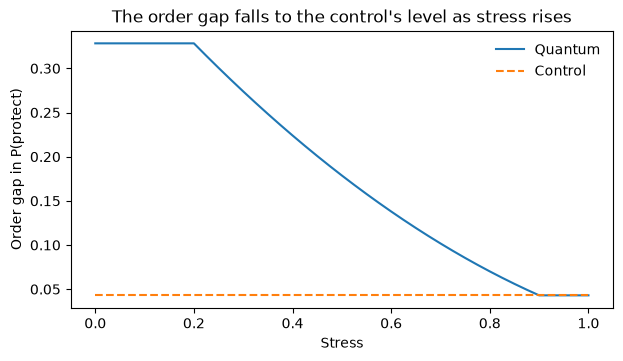

Stress 0.15: quantum gap 0.328. Stress 1.0: quantum 0.043, control 0.043


In [7]:
stresses = np.linspace(0, 1, 41)
gaps_quantum, gaps_control = [], []
for stress in stresses:
    for gaps, decide in ((gaps_quantum, quantum_decide), (gaps_control, classical_mixture_decide)):
        a, b = (decide({**start, "stress": float(stress), "recent_events": order})["quantum"]["p_protect"] for order in (["tremor", "gas_plume"], ["gas_plume", "tremor"]))
        gaps.append(abs(a - b))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(stresses, gaps_quantum, label="Quantum")
ax.plot(stresses, gaps_control, "--", label="Control")
ax.set_xlabel("Stress")
ax.set_ylabel("Order gap in P(protect)")
ax.set_title("The order gap falls to the control's level as stress rises")
ax.legend(frameon=False)
plt.show()
print(f"Stress 0.15: quantum gap {np.interp(0.15, stresses, gaps_quantum):.3f}. Stress 1.0: quantum {gaps_quantum[-1]:.3f}, control {gaps_control[-1]:.3f}")

## 6. On a noisy simulated device

Next we run the same decision circuit with the noise of an IBM device. **This is `FakeTorino`, a simulator using a saved calibration snapshot. No job has run on real IBM hardware.**

Device noise and our model's stress are different things. We measure here how well the circuit survives realistic noise, and the delay experiment below shows real-device-style decoherence over idle time.

In [8]:
from qiskit import transpile
from qiskit_aer.primitives import SamplerV2
from qiskit_ibm_runtime.fake_provider import FakeTorino

backend = FakeTorino()
sampler = SamplerV2.from_backend(backend, seed=42)
SHOTS = 4000
print(f"{'Order':<26}{'Exact':<9}{'FakeTorino':<12}{'Std. error':<12}Two-qubit gates")
for order in (["tremor", "gas_plume"], ["gas_plume", "tremor"]):
    circuit = transpile(build_decision_circuit(0.85, order, Q_SAFE, Q_DANGER, ETA), backend, optimization_level=3, seed_transpiler=42)
    counts = sampler.run([circuit], shots=SHOTS).result()[0].data.c.get_counts()
    measured = counts.get("1", 0) / SHOTS
    print(f"{' then '.join(order):<26}{closed_form(0.85, order):<9.3f}{measured:<12.3f}{np.sqrt(measured * (1 - measured) / SHOTS):<12.4f}{circuit.count_ops().get('cz', 0)}")

Order                     Exact    FakeTorino  Std. error  Two-qubit gates


tremor then gas_plume     0.374    0.375       0.0077      2


gas_plume then tremor     0.556    0.567       0.0078      2


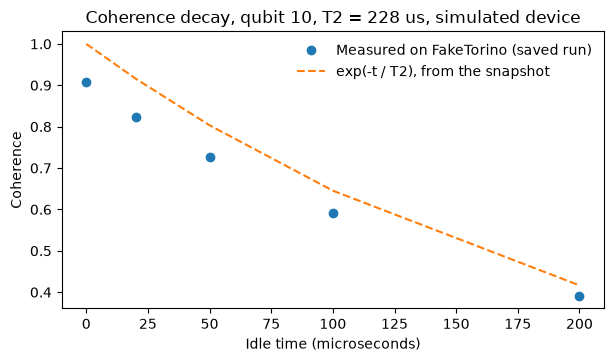

Source: fake_torino | qiskit_ibm_runtime.fake_provider.FakeTorino snapshot | 2026-11-04
Measured values start near 0.91, not 1, because the noise snapshot also includes gate and readout errors.


In [9]:
delay = json.loads((ROOT / "mind/results/delay_experiment.json").read_text(encoding="utf-8"))
rows = delay["rows"]
times = [r["t_us"] for r in rows]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(times, [r["coherence_x_measured"] for r in rows], "o", label="Measured on FakeTorino (saved run)")
ax.plot(times, [r["coherence_theory_exp_t_over_t2"] for r in rows], "--", label="exp(-t / T2), from the snapshot")
ax.set_xlabel("Idle time (microseconds)")
ax.set_ylabel("Coherence")
ax.set_title(f"Coherence decay, qubit {delay['probe_qubit']}, T2 = {delay['t2_us']:.0f} us, simulated device")
ax.legend(frameon=False)
plt.show()
print("Source:", delay["backend"], "|", delay["calibration_source"], "|", delay["date"][:10])
print("Measured values start near 0.91, not 1, because the noise snapshot also includes gate and readout errors.")

## 7. In a full simulation

The mind now plays a whole run: an evacuation on a fictional volcanic island, 36 two-hour steps. Each mind sees the same worlds, and the world never tells it the future.

We use three minds: quantum, its control, and a rule-based classical mind. Two things to watch: how often the minds disagree, and whether the quantum mind survives more. **We find no evidence that it does, and we don't claim that it should.**

With 60 seeds, a gap of a few runs is within noise, so don't read small differences below as real. Only 41 of these 60 volcano seeds erupt, and leaving early costs little in this scenario, so high survival there is partly built in.

In [10]:
from collections import Counter

import contracts
from engine.simulation import SimulationEngine

SEEDS = range(1000, 1060)
minds = {"Quantum": "quantum", "Control": "classical_mixture", "Classical": "classical"}
print(f"{len(SEEDS)} seeds each\n{'Scenario':<10}{'Mind':<11}{'Survived':<10}Causes of death")
for scenario in ("volcano", "island"):
    for label, mind in minds.items():
        survived, causes = 0, Counter()
        for seed in SEEDS:
            run = SimulationEngine(seed=seed, mind_type=mind, noise_source="stub", scenario=scenario).run()
            survived += run["outcome"] == "survived"
            if run["outcome"] != "survived":
                causes[run["cause"]] += 1
        print(f"{scenario:<10}{label:<11}{survived / len(SEEDS):<10.1%}{dict(causes)}")

60 seeds each
Scenario  Mind       Survived  Causes of death


volcano   Quantum    100.0%    {}


volcano   Control    98.3%     {'exhaustion_collapse': 1}


volcano   Classical  100.0%    {}


island    Quantum    93.3%     {'hypothermia': 3, 'exhaustion_collapse': 1}


island    Control    90.0%     {'hypothermia': 6}


island    Classical  95.0%     {'hypothermia': 3}


In [11]:
differs = {"control": 0, "classical": 0, "swap": 0}
steps = pairs = 0


def probe(state):
    global steps, pairs
    decision = quantum_decide(state)
    steps += 1
    differs["control"] += classical_mixture_decide(state)["action"] != decision["action"]
    differs["classical"] += contracts.classical_decide(state)["action"] != decision["action"]
    events = state["recent_events"]
    real = [i for i, e in enumerate(events) if e != "none"]
    if len(real) >= 2 and events[real[-1]] != events[real[-2]]:
        pairs += 1
        swapped = list(events)
        swapped[real[-1]], swapped[real[-2]] = swapped[real[-2]], swapped[real[-1]]
        differs["swap"] += quantum_decide({**state, "recent_events": swapped})["action"] != decision["action"]
    return decision


for seed in SEEDS:
    SimulationEngine(seed=seed, mind_type="quantum", noise_source="stub", decide_fn=probe, scenario="volcano").run()
print(f"Over {steps} decisions the quantum mind actually faced on the volcano:")
print(f"  Its control would choose differently {differs['control'] / steps:.1%} of the time")
print(f"  The classical mind would choose differently {differs['classical'] / steps:.1%} of the time")
print(f"  Swapping the last two different signs changes its action {differs['swap'] / steps:.1%} of the time ({differs['swap']} of {pairs} steps where a swap was possible)")

Over 2157 decisions the quantum mind actually faced on the volcano:
  Its control would choose differently 9.0% of the time
  The classical mind would choose differently 33.3% of the time
  Swapping the last two different signs changes its action 4.5% of the time (96 of 889 steps where a swap was possible)


## 8. Is the world believable? Testing it against the real eruption

Critics of a simulation will ask how we know it's right. We can't claim "correct". We can test specific claims against reality, with targets committed *before* the model first ran, and report the failures.

So we built a second engine on the real St Vincent: real satellite terrain, real wind, the published event timeline and real walking times. A checker reads each scenario's parts and reports only what they can support. **Agreement measured in one place never carries over to another, and a result counts only if the test was blind.**

In [12]:
from stranded_physics import check, gates

card = check.read_card(ROOT / "stranded_physics/scenario_cards/st_vincent_2021.toml")
print(check.report(card, [check.assess(category, card.id) for category in card.uses]))

Scenario: La Soufriere, St Vincent, April 2021 (st_vincent_2021), real place

Part      Model  Own tests  Agrees  Disagrees  Assumed values
terrain   yes    PASS       0       0          11 of 11
atmos     yes    PASS       0       0          1 of 1
eruption  yes    PASS       0       0          28 of 92
tephra    yes    PASS       0       0          27 of 27
exposure  yes    PASS       0       0          6 of 7
pdc       yes    PASS       1       2          7 of 9
lahar     yes    PASS       0       0          5 of 5
agent     yes    PASS       0       0          12 of 17

Result: PARTLY VALIDATED

Agrees with reality:
  pdc: Dense flows reach the sea on the west flank

Disagrees with reality:
  pdc: Share of flow cells touching the sea that lie off the west flank
  pdc: Flows on the southeast flank stop near the crater

Reference checks failing:
  terrain: Highest land cell lies near the catalogued summit position

Reported, not scored:
  terrain: Share of drainage channels unchanged

In [13]:
recorded = gates.read_verdicts("pdc")
print("Hot-flow checks against Cole et al. (recorded results):")
for gate_id, label in (("pdc-reaches-west-sea", "Reaches the sea on the west flank (1 = yes)"), ("pdc-sea-only-on-west", "Share of sea-edge flow cells off the west flank, want 0"), ("pdc-southeast-reach", "Reach on the southeast flank, want about 1.8 km")):
    print(f"  {recorded[gate_id]['verdict']:<6}{label}: {recorded[gate_id]['value']:.2f}")
mass = gates.read_verdicts("eruption")["eruption-total-mass"]
print(f"\nModelled erupted mass to 12 April: {mass['model_kg']:.2e} kg. Published whole-eruption fallout: {mass['cole_whole_eruption_kg']:.2e} kg, so {mass['model_kg'] / mass['cole_whole_eruption_kg']:.1f} times too high.")
print("Ash passes aren't counted: we changed the grain model after the first run missed Barbados, so those tests are no longer blind.")

Hot-flow checks against Cole et al. (recorded results):
  PASS  Reaches the sea on the west flank (1 = yes): 1.00
  FAIL  Share of sea-edge flow cells off the west flank, want 0: 0.44
  FAIL  Reach on the southeast flank, want about 1.8 km: 8.14

Modelled erupted mass to 12 April: 3.10e+11 kg. Published whole-eruption fallout: 8.88e+10 kg, so 3.5 times too high.
Ash passes aren't counted: we changed the grain model after the first run missed Barbados, so those tests are no longer blind.


The same parts can build a new scenario. Here a real storm, Hurricane Beryl in 2024, reuses the terrain, weather and walking parts, and only the storm itself is new. Nothing has been scored yet, because we hold no wind observations from St Vincent for that storm, and the checker says so rather than implying a pass.

In [14]:
card = check.read_card(ROOT / "stranded_physics/scenario_cards/beryl_2024.toml")
print(check.report(card, [check.assess(category, card.id) for category in card.uses]))
beryl = gates.read_verdicts("storm")["storm-beryl-peak"]
print(f"\nModelled peak wind at Kingstown: {beryl['peak_m_s']:.1f} m/s at {beryl['time_utc']}, with the storm's centre {beryl['closest_km']:.0f} km away at closest.")

Scenario: Hurricane Beryl near St Vincent, July 2024 (beryl_2024), real place

Part      Model  Own tests  Agrees  Disagrees  Assumed values
terrain   yes    PASS       0       0          11 of 11
atmos     yes    PASS       0       0          1 of 1
storm     yes    PASS       0       0          18 of 25
agent     yes    PASS       0       0          12 of 17
exposure  yes    PASS       0       0          6 of 7

Result: VERIFIED, NOT VALIDATED HERE

Reported, not scored:
  storm: Peak modelled wind at Kingstown during Hurricane Beryl (reported, no target) (NO_TARGET)
  storm: Named storms per year near St Vincent since 1980 (reported, no target) (NO_TARGET)

Modelled peak wind at Kingstown: 42.6 m/s at 2024-07-01T15:00:00Z, with the storm's centre 76 km away at closest.


These last results were recorded when each check last ran. Rebuilding the St Vincent pack needs raw data files that aren't stored in the repo while their licences are being confirmed.

## 9. Where this falls short

- **No real hardware.** Everything quantum here runs on a simulator or an exact calculation.
- **One fitted parameter.** `ETA` is solved from one published result, and all event angles are our choices. So the order gap's size is a property of those choices, not a measurement of people. We have no human data for tremor and gas.
- **The control still shows some order effect, and it flips the same action.** Only the gap's size separates the minds.
- **No survival advantage.** On the volcano the classical mind does at least as well.
- **The classical baseline is hand-set.** The time-use data file is loaded but its numbers don't drive decisions.
- **The real-world flow model fails 2 of its 3 blind checks.** A simple energy cone spreads flows too widely, and no setting we tried passes all three. A depth-averaged solver is also built, and it fails the other way: its flows stop about 2.5 km out and never reach the sea. Neither model passes all three.
- **Erupted mass is over 3 times too high,** so ash amounts can't be trusted.
- **Survival on the real island says nothing about real people.** The body now follows published water and energy limits, but the odds of surviving a flow are assumptions, not fitted to casualty data.
- **In the fictional scenario, rates are assumed,** and they were tuned so that decisions carry stakes.

**Next:** ash and flow maps of the 2021 eruption to test against, a channelled release for the flow solver, and a run on real IBM hardware.

## References

- Busemeyer, J. R., and Bruza, P. D. (2012). *Quantum Models of Cognition and Decision.* Cambridge University Press.
- Tversky, A., and Shafir, E. (1992). The disjunction effect in choice under uncertainty. *Psychological Science*, 3(5), 305-309.
- Pothos, E. M., and Busemeyer, J. R. (2009). A quantum probability explanation for violations of 'rational' decision theory. *Proceedings of the Royal Society B*, 276, 2171-2178.
- Cole, P. D., et al. (2023). Explosive sequence of La Soufriere St Vincent April 2021: insights into drivers and consequences via eruptive products. *Geological Society, London, Special Publications*, 539. doi:10.1144/SP539-2022-292.
- Malin, M. C., and Sheridan, M. F. (1982). Computer-assisted mapping of pyroclastic surges. *Science*, 217, 637-640.
- Holland, G. J. (1980). An analytic model of the wind and pressure profiles in hurricanes. *Monthly Weather Review*, 108, 1212-1218.
- Copernicus DEM GLO-30, ESA WorldCover 2021, Open-Meteo and IBTrACS data, as recorded in each `datasets.toml`.
